## Policy Evaluation: four TD methods and the TOMC baseline

We compare four online evaluators using two feature matrices (tabular and shared linear features) on each environment. The TOMC baseline is included in both Q-error and V-value graphs. The policy is fixed during evaluation; all methods minimize costs.

The underlying stochastic TD formula:

$(\widetilde F_t(\theta_t)=\phi_t\left(\phi_t^\top\theta_t-c_t-\gamma\phi_{t+1}^\top\theta_t\right),\qquad \theta_{t+1}=\theta_t-\eta\widetilde F_t(\theta_t).)$

With $\delta_t=c_t+\gamma\phi_{t+1}^\top\theta_t-\phi_t^\top\theta_t$, the update is $\theta_{t+1}=\theta_t+\eta\delta_t\phi_t$.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Run from the project root or notebooks/ using the current source package.
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").exists())
sys.path.insert(0, str(root / "src"))

from ie692_rl.envs import GridWorld, Blackjack
from ie692_rl.core.policy import check_policy
from ie692_rl.enhancements.true_online_td import (
    tabular_features, linear_features,
    estimated_state_value, td_zero, td_lambda, td_lambda_sarsa, true_online_td_lambda,
)

plt.style.use("ggplot")

# Use the same four methods in the original comparison and grid search.
methods = {
    "TD(0)": td_zero,
    "TD(λ): accumulated operators": td_lambda,
    "SARSA(λ): eligibility traces": td_lambda_sarsa,
    "True Online TD(λ)": true_online_td_lambda,
}

ENVIRONMENTS = ["blackjack", "gridworld"]
N_STEPS = 200000           # Online training transitions per method
RECORD_EVERY = 100
ETA = 0.05
LAM = 0.8
SEED = 42
REFERENCE_ROLLOUTS = 300 # Independent validation only; not training
REFERENCE_HORIZON = 80
RUN_TOMC = True           # Include the baseline in both comparisons
TOMC_BIAS = 0.01          # Discount-tail stopping tolerance

output = root / "policy_evaluation_results"
output.mkdir(exist_ok=True)

$\|\widetilde Q^\pi-Q^\pi\|_W = \sqrt{\sum_{s,a}w(s,a)(\widetilde Q^\pi(s,a)-Q^\pi(s,a))^2}.)$ 

For simplicity, use uniform weights, $w(s,a)=1/(|\mathcal S||\mathcal A|)$, for both environments. Thus this is the root-mean-squared Q error, a valid weighted norm, but not the stationary-distribution weighting used in some lecture examples.

Below, $P$ and $c$ describe the known environment rules for computing a reference $Q^\pi$. TD training still calls only env.step_one()

### State-value performance at a fixed evaluation state

For any policy, $V^\pi(s)=\sum_a\pi(a\mid s)Q^\pi(s,a)$. We apply the same
policy-weighted average to each learned Q estimate. Use GridWorld's origin
(row 0, column 0) and Blackjack's player total 8 with dealer visible card 3.
These states remain fixed across methods and feature sets.

In this notebook the policy is fixed, so $\widehat V_t^\pi(s_0)$ should approach
the reference $V^\pi(s_0)$ as the TD iteration $t$ increases. A lower estimate
alone does not indicate greater accuracy. In policy optimization, $\pi_t$
changes and $V^{\pi_t}(s_0)$ instead measures the changing policy's cost.

`estimated_state_value(Q, pi, state)` computes the policy-weighted average.
`state_value_performance(...)` returns the estimate, exact reference, absolute
value error, iteration, and cumulative observations. Each TD update uses one
online transition. Scalar V estimates are recorded **after every update**,
including initialization at iteration 0; full Q snapshots remain spaced by
`RECORD_EVERY` to limit memory. Computing these metrics uses no extra environment
observations. Both the original and tuned runs save **separate Q-error and
V-value plots**, along with CSV histories, in `policy_evaluation_results/`.

In [2]:
def reference_q(env, pi):
    """Exact fixed-policy Q from known environment rules; only for plotting."""
    S, A = env.n_states, env.n_actions
    P = np.zeros((S, A, S))
    c = np.zeros((S, A))

    if isinstance(env, GridWorld):
        directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]
        for s in range(S):
            r, col = divmod(s, env.cols)
            special = s in env.goals or s in env.hazards
            c[s, :] = 0 if s in env.goals else 1 if s in env.hazards else 0.2
            for a in range(A):
                if special:
                    P[s, a, env.start] += 1 - env.q
                for actual, (dr, dc) in enumerate(directions):
                    probability = env.p if actual == a else (1 - env.p) / 3
                    rr = min(env.rows - 1, max(0, r + dr))
                    cc = min(env.cols - 1, max(0, col + dc))
                    P[s, a, rr * env.cols + cc] += probability * (env.q if special else 1)

    else:  # Blackjack: dealer's hidden card and draws are uniformly 2,3,4,5
        def dealer_outcomes(visible):
            active = {visible: 1.0}
            finished = {}
            while active:
                new = {}
                for total, prob in active.items():
                    for card in range(2, 6):
                        new_total = total + card
                        dest = finished if new_total >= 9 else new
                        dest[new_total] = dest.get(new_total, 0) + prob / 4
                active = new
            return finished

        for s in range(S):
            player, dealer = env.decode(s)
            c[s, 0] = sum(
                probability * (-1 if total > 11 or player > total else
                               1 if player < total else 0)
                for total, probability in dealer_outcomes(dealer).items()
            )
            for card in range(2, 6):
                if player + card > 11:
                    c[s, 1] += 0.25
                else:
                    P[s, 1, env.encode(player + card, dealer)] += 0.25

    P_pi = np.einsum('sa,sat->st', pi, P)
    c_pi = (pi * c).sum(axis=1)
    V = np.linalg.solve(np.eye(S) - env.gamma * P_pi, c_pi)
    return c + env.gamma * np.einsum('sat,t->sa', P, V)


def weighted_error(Q_t, Q_reference):
    # Uniform W = I / (|S||A|)
    return float(np.sqrt(np.mean((Q_t - Q_reference) ** 2)))


def state_value_performance(value_history, Q_reference, pi, state):
    """Build per-update fixed-policy state-value performance measurements."""
    reference = estimated_state_value(Q_reference, pi, state)
    iterations = np.arange(len(value_history))
    return pd.DataFrame(dict(
        iteration=iterations, observations=iterations,
        evaluation_state=state, estimated_value=value_history,
        reference_value=reference,
        absolute_value_error=np.abs(value_history - reference),
    ))


def tomc(env, pi, rng, bias=0.01, pi_min=None,
         max_observations=200_000, log_transition=None):
    """First-visit TOMC with dynamic exploration time (continuous on-policy data).

    Each required (state, action) is visited once, then sampling continues until
    the discount tail after the latest first visit is small enough. Blackjack
    returns stop at the end of each hand; the next hand is a fresh deal.

    Returns (Q, number_of_observations). Costs must be at most 1, as in both
    project environments; unrequired actions receive the upper bound 1/(1-gamma).
    """
    check_policy(pi, env.n_states, env.n_actions)
    gamma = env.gamma
    if not 0 < gamma < 1:
        raise ValueError("gamma must be between 0 and 1")
    if pi_min is None:
        pi_min = (1 - gamma) / env.n_actions
    if not 0 < pi_min <= 1 or bias <= 0 or max_observations < 1:
        raise ValueError("Invalid threshold, bias, or observation limit")

    required = pi >= pi_min
    if not required.any():
        raise ValueError("No state-action pairs meet pi_min")

    first = np.full(pi.shape, -1, dtype=int)
    Q = np.full(pi.shape, 1 / (1 - gamma), dtype=float)
    trajectory = []
    state = env.reset(rng)

    for t in range(max_observations):
        action = int(rng.choice(env.n_actions, p=pi[state]))
        next_state, cost, done = env.step_one(state, action, rng)
        trajectory.append((state, action, float(cost), bool(done)))
        if log_transition is not None:
            log_transition(state, action, cost, next_state, done)

        if required[state, action] and first[state, action] == -1:
            first[state, action] = t

        n = t + 1
        if np.all(first[required] >= 0):
            longest_tail_error = gamma ** (n - first[required].max())
            if longest_tail_error <= bias * (1 - gamma):
                break

        state = env.reset(rng) if done else next_state
    else:
        covered = int((first[required] >= 0).sum())
        raise RuntimeError(
            f"TOMC incomplete: {covered}/{int(required.sum())} pairs "
            f"after {max_observations} observations"
        )

    # Backward discounted returns, restarting at episode boundaries.
    G = 0.0
    for t in range(n - 1, -1, -1):
        s, a, cost, done = trajectory[t]
        G = cost + (0.0 if done else gamma * G)
        if required[s, a] and first[s, a] == t:
            Q[s, a] = G

    return Q, n


def run_tomc_with_history(env, pi, Q_reference, state, budget, seed,
                          bias=0.01, record_every=100):
    """Track first-visit return prefixes using the callback-enabled TOMC helper."""
    required = pi >= (1 - env.gamma) / env.n_actions
    required_pairs = int(required.sum())
    seen = np.zeros_like(required)
    Q_prefix = np.full(pi.shape, 1 / (1 - env.gamma), dtype=float)
    weights = np.zeros_like(Q_prefix)
    values = np.empty(budget + 1, dtype=float)
    coverage = np.zeros(budget + 1, dtype=int)
    values[0] = estimated_state_value(Q_prefix, pi, state)
    observations = 0
    covered = 0
    q_rows = [dict(observations=0, weighted_error=weighted_error(Q_prefix, Q_reference),
                   covered_pairs=0)]

    def log_transition(s, a, cost, next_state, done):
        nonlocal observations, covered
        if required[s, a] and not seen[s, a]:
            seen[s, a] = True
            covered += 1
            Q_prefix[s, a] = 0.0
            weights[s, a] = 1.0
        # Add this cost to every still-active first-visit discounted return.
        Q_prefix[:] += weights * cost
        weights[:] *= env.gamma
        if done:
            weights.fill(0.0)  # A return never crosses a Blackjack hand boundary.
        observations += 1
        values[observations] = estimated_state_value(Q_prefix, pi, state)
        coverage[observations] = covered
        if record_every and observations % record_every == 0:
            q_rows.append(dict(observations=observations,
                               weighted_error=weighted_error(Q_prefix, Q_reference),
                               covered_pairs=covered))

    try:
        Q, count = tomc(env, pi, np.random.default_rng(seed), bias=bias,
                        max_observations=budget, log_transition=log_transition)
        completed = True
        status = "completed"
    except RuntimeError as error:
        if not str(error).startswith("TOMC incomplete:"):
            raise
        Q, count = Q_prefix.copy(), observations
        completed = False
        status = "incomplete coverage" if covered < required_pairs else "tail criterion unmet"

    # Always retain the actual stopping point, even between Q checkpoints.
    final_row = dict(observations=count, weighted_error=weighted_error(Q, Q_reference),
                     covered_pairs=covered)
    if q_rows[-1]["observations"] == count:
        q_rows[-1] = final_row
    else:
        q_rows.append(final_row)
    values[count] = estimated_state_value(Q, pi, state)
    q_history = pd.DataFrame(q_rows)
    value_history = state_value_performance(values[:count + 1], Q_reference, pi, state)
    value_history["covered_pairs"] = coverage[:count + 1]
    label = "TOMC baseline" if completed else f"TOMC ({status})"
    for data in [q_history, value_history]:
        data["method"] = label
        data["seed"] = seed
        data["required_pairs"] = required_pairs
        data["run_completed"] = completed
        data["estimate_complete"] = completed & (data.observations == count)
        data["status"] = status
    summary = dict(method=label, seed=seed, observations=count, observation_budget=budget,
                   bias=bias, covered_pairs=covered, required_pairs=required_pairs,
                   completed=completed, status=status,
                   weighted_error=final_row["weighted_error"],
                   estimated_value=values[count],
                   reference_value=estimated_state_value(Q_reference, pi, state))
    return dict(Q=Q, q_history=q_history, value_history=value_history, summary=summary)


def plot_td_performance(q_data, value_data, environment, features, tuned=False,
                        tomc_result=None):
    """Save separate Q-error and V(s0) comparisons, including TOMC when supplied."""
    environment_name = {"blackjack": "Blackjack", "gridworld": "GridWorld"}[environment]
    state_label = "player 8, dealer 3" if environment == "blackjack" else "origin (0, 0)"
    run_label = "tuned" if tuned else "original"
    suffix = "td_tuned" if tuned else "td"
    prefix = f"{environment}_{features.lower()}_{suffix}"
    colors = dict(zip(methods, plt.rcParams["axes.prop_cycle"].by_key()["color"]))
    for metric, data, column, ylabel in [
        ("error", q_data, "weighted_error", "Weighted Q error"),
        ("value", value_data, "estimated_value", "Estimated discounted cost V(s0)"),
    ]:
        fig, ax = plt.subplots(figsize=(8, 5))
        for method, group in data.groupby("method", sort=False, observed=True):
            ax.plot(group.observations, group[column], label=method, color=colors[method])
        if tomc_result is not None:
            baseline = tomc_result["q_history" if metric == "error" else "value_history"]
            info = tomc_result["summary"]
            label = f"{info['method']} ({info['observations']:,} obs)"
            ax.plot(baseline.observations, baseline[column], color="tab:green",
                    linestyle="--", linewidth=1.8, label=label)
            ax.plot(baseline.observations.iloc[-1], baseline[column].iloc[-1],
                    color="tab:green", marker="o", markersize=6)
        if metric == "value":
            ax.axhline(value_data.reference_value.iloc[0], color="black",
                       linestyle="--", label="Exact fixed-policy value")
        ax.set(title=f"{environment_name}: {run_label} policy evaluation ({features})"
                     + (f"\nEvaluation state: {state_label}" if metric == "value" else ""),
               xlabel="Cumulative online observations", ylabel=ylabel)
        ax.legend(fontsize=8)
        fig.tight_layout()
        fig.savefig(output / f"{prefix}_{metric}.png", dpi=160)
        plt.show()
        plt.close(fig)

## Run the eight configurations per environment

Each environment uses four methods with both tabular and shared linear features.
All methods use the same fixed policy, seed, and observation budget. In particular,
SARSA(λ) is used for policy evaluation here; it does not improve the policy.

The methods differ in what they remember:

- **TD(0)** uses only the current TD error and current features:
  $\theta_{t+1}=\theta_t+\eta\delta_t\phi_t$.
- **TD(λ): accumulated operators** (`td_lambda`) remembers past TD errors
  multiplied by the features from those steps. With
  $\widetilde F_t=-\delta_t\phi_t$, its updates are
  $z_t=\lambda z_{t-1}+\widetilde F_t$ and
  $\theta_{t+1}=\theta_t-\eta z_t$.
- **SARSA(λ): eligibility traces** (`td_lambda_sarsa`) remembers previously
  visited feature vectors, then applies the **current** TD error to the trace:
  $e_t=\gamma\lambda e_{t-1}+\phi_t$ and
  $\theta_{t+1}=\theta_t+\eta\delta_t e_t$.
- **True Online TD(λ)** uses the Dutch trace
  $e_t=\gamma\lambda e_{t-1}+(1-\eta\gamma\lambda e_{t-1}^{\top}\phi_t)\phi_t$
  and its true-online correction to the parameter update.

The accumulated TD operator uses λ decay, while the SARSA eligibility trace
uses γλ decay. Past errors in the operator sum were computed with the parameter
vectors at their respective steps. These are different updates when λ is nonzero;
both reduce to TD(0) when λ = 0. The accumulated operator and eligibility traces
reset after Blackjack termination; GridWorld is continuing.

Record V(s0) after every update and Q error at the configured snapshot interval.
Save both plots and their CSV histories for all four methods.

In [3]:
all_results = {}
all_value_results = {}

for name in ENVIRONMENTS:
    env = Blackjack() if name == "blackjack" else GridWorld()
    pi = np.full((env.n_states, env.n_actions), 1 / env.n_actions)
    Q_reference = reference_q(env, pi)
    s_0 = env.encode(8, 3) if name == "blackjack" else env.start

    records = []
    value_frames = []
    for feature_name, feature_fn in [
        ("Tabular", tabular_features),
        ("Linear", linear_features),
    ]:
        Phi = feature_fn(env)
        for method_name, td_fn in methods.items():
            value_history = np.empty(N_STEPS + 1, dtype=float)
            kwargs = dict(env=env, pi=pi, features=Phi, n_steps=N_STEPS,
                          eta=ETA, rng=np.random.default_rng(SEED),
                          record_every=RECORD_EVERY,
                          evaluation_state=s_0, value_history=value_history)
            if td_fn != td_zero:
                kwargs["lam"] = LAM
            history = []
            result = td_fn(**kwargs, q_history=history)
            Q, n_samples = result.q, result.observations

            snapshots = [(0, np.zeros_like(Q))] + history
            if snapshots[-1][0] != n_samples:
                snapshots.append((n_samples, Q))
            for iteration, Q_t in snapshots:
                records.append(dict(features=feature_name, method=method_name,
                                    iteration=iteration, observations=iteration,
                                    weighted_error=weighted_error(Q_t, Q_reference)))
            values = state_value_performance(value_history, Q_reference, pi, s_0)
            values["features"] = feature_name
            values["method"] = method_name
            value_frames.append(values)
            print(f"{name:10} | {feature_name:7} | {method_name:18} | "
                  f"parameters={Phi.n_features:3} | observations={n_samples}")

    results = pd.DataFrame(records)
    value_results = pd.concat(value_frames, ignore_index=True)
    all_results[name] = results
    all_value_results[name] = value_results
    results.to_csv(output / f"{name}_td_history.csv", index=False)
    value_results.to_csv(output / f"{name}_td_value_history.csv", index=False)

blackjack  | Tabular | TD(0)              | parameters= 64 | observations=200000
blackjack  | Tabular | TD(λ): accumulated operators | parameters= 64 | observations=200000
blackjack  | Tabular | SARSA(λ): eligibility traces | parameters= 64 | observations=200000
blackjack  | Tabular | True Online TD(λ)  | parameters= 64 | observations=200000
blackjack  | Linear  | TD(0)              | parameters= 16 | observations=200000
blackjack  | Linear  | TD(λ): accumulated operators | parameters= 16 | observations=200000
blackjack  | Linear  | SARSA(λ): eligibility traces | parameters= 16 | observations=200000
blackjack  | Linear  | True Online TD(λ)  | parameters= 16 | observations=200000
gridworld  | Tabular | TD(0)              | parameters=400 | observations=200000
gridworld  | Tabular | TD(λ): accumulated operators | parameters=400 | observations=200000
gridworld  | Tabular | SARSA(λ): eligibility traces | parameters=400 | observations=200000
gridworld  | Tabular | True Online TD(λ)  | param

## TOMC baseline for the Q and V graphs

Run the callback-enabled `tomc()` helper above (preserving the original baseline) once per environment and comparison seed, with
`bias=TOMC_BIAS` and the same `N_STEPS` observation cap as TD. Original runs use
`SEED`; tuned TD comparisons use `SEED + 1`. TOMC has no feature matrix, so the
same baseline trajectory is reused in both tabular and linear-feature plots.

The existing `log_transition` callback tracks **first-visit return prefixes**:
a new required state-action pair starts a return with discount weight 1, each
observed cost is added using the active weights, weights decay by gamma, and
terminal transitions reset them. This records V after every observation and
Q error at `RECORD_EVERY` checkpoints without extra environment observations.
The initial estimate for unvisited pairs is TOMC's upper bound `1/(1-gamma)`.

Intermediate estimates are **provisional**. A completed run still uses TOMC's
original coverage and discount-tail stopping rules and its returned Q table.
If the cap is reached, the curve retains its observed return prefixes and is
explicitly labeled **incomplete coverage** (or **tail criterion unmet**). Such a
curve is not presented as a completed TOMC result; CSVs include coverage counts,
completion status, and actual cumulative observations. Curves end at the actual
stopping point, marked by a circle, and are not extended with extra observations.

Save TOMC Q/V histories and `tomc_summary.csv` alongside the 16 comparison plots.
Set `RUN_TOMC = False` to produce the TD-only comparisons.


In [4]:
tomc_results = {"original": {}, "tuned": {}}
tomc_summary_rows = []
if RUN_TOMC:
    for comparison, seed in [("original", SEED), ("tuned", SEED + 1)]:
        for name in ENVIRONMENTS:
            env = Blackjack() if name == "blackjack" else GridWorld()
            pi = np.full((env.n_states, env.n_actions), 1 / env.n_actions)
            s_0 = env.encode(8, 3) if name == "blackjack" else env.start
            result = run_tomc_with_history(
                env, pi, reference_q(env, pi), s_0, N_STEPS, seed,
                bias=TOMC_BIAS, record_every=RECORD_EVERY,
            )
            tomc_results[comparison][name] = result
            for key, suffix in [("q_history", "history"), ("value_history", "value_history")]:
                data = result[key]
                data["environment"] = name
                data["comparison"] = comparison
                data.to_csv(output / f"{name}_{comparison}_tomc_{suffix}.csv", index=False)
            info = dict(result["summary"], environment=name, comparison=comparison)
            tomc_summary_rows.append(info)
            print(f"{comparison} | {name} | {info['method']}: "
                  f"observations={info['observations']:,}, "
                  f"coverage={info['covered_pairs']}/{info['required_pairs']}")
    tomc_summary = pd.DataFrame(tomc_summary_rows)
    tomc_summary.to_csv(output / "tomc_summary.csv", index=False)
    display(tomc_summary)

original | blackjack | TOMC baseline: observations=544, coverage=64/64
original | gridworld | TOMC (incomplete coverage): observations=200,000, coverage=396/400
tuned | blackjack | TOMC baseline: observations=736, coverage=64/64
tuned | gridworld | TOMC (incomplete coverage): observations=200,000, coverage=398/400


,method,seed,observations,observation_budget,bias,covered_pairs,required_pairs,completed,status,weighted_error,estimated_value,reference_value,environment,comparison
0,TOMC baseline,42,544,200000,0.01,64,64,True,completed,0.508094,0.000000,0.540625,blackjack,original
1,TOMC (incomplete coverage),42,200000,200000,0.01,396,400,False,incomplete coverage,0.830553,2.181397,2.287034,gridworld,original
2,TOMC baseline,43,736,200000,0.01,64,64,True,completed,0.685438,0.000000,0.540625,blackjack,tuned
3,TOMC (incomplete coverage),43,200000,200000,0.01,398,400,False,incomplete coverage,0.643093,2.340570,2.287034,gridworld,tuned


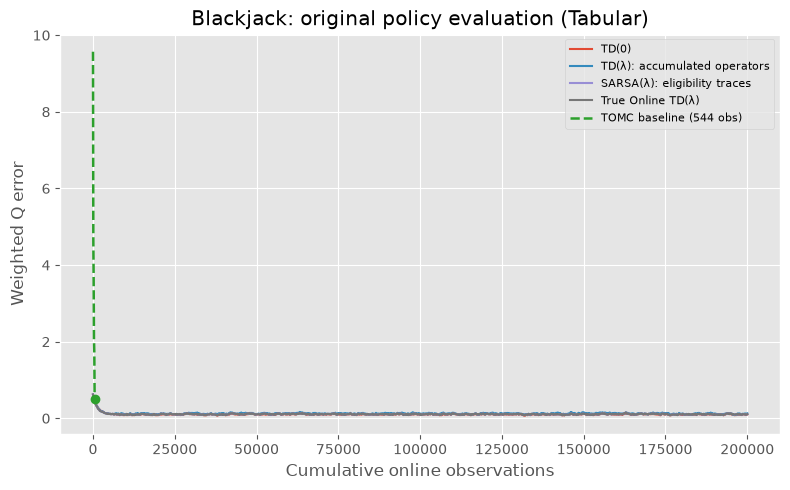

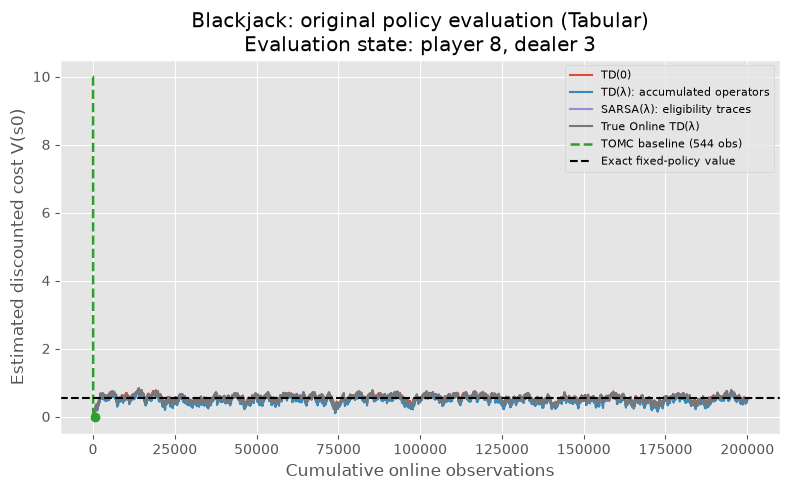

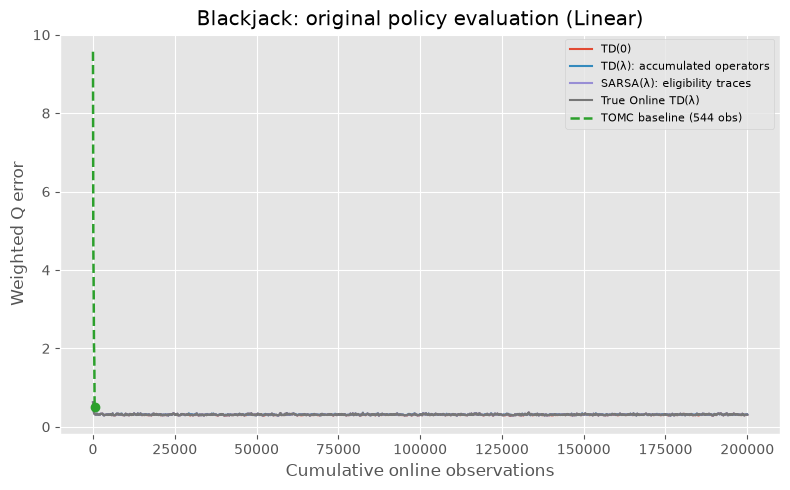

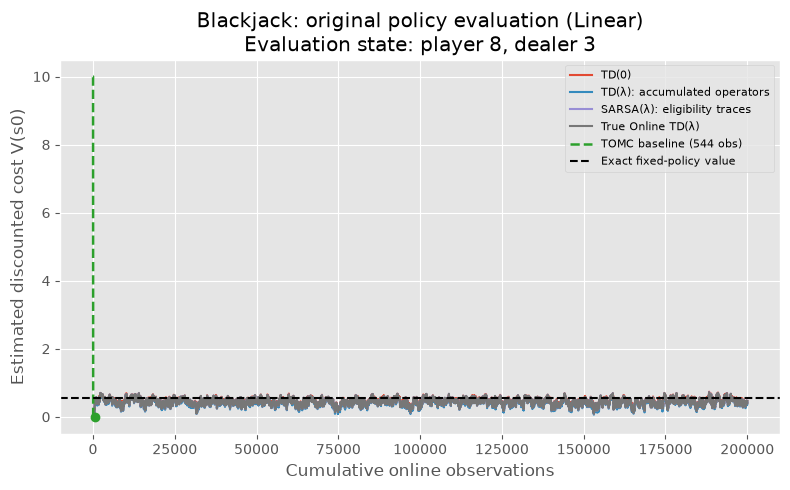

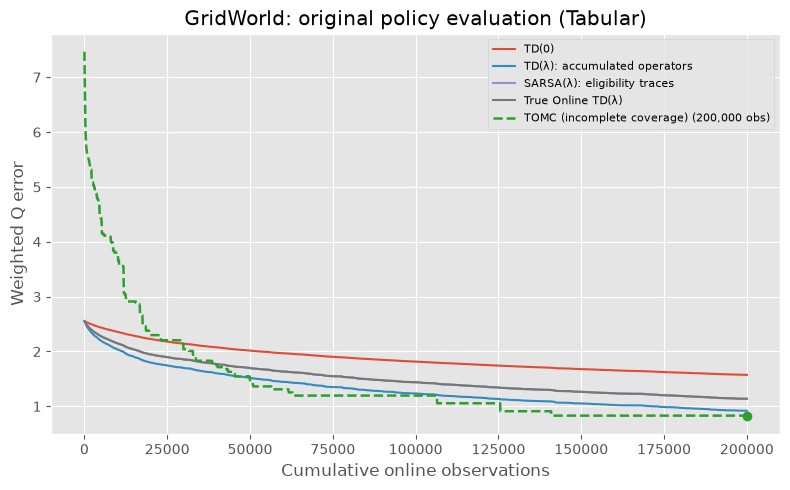

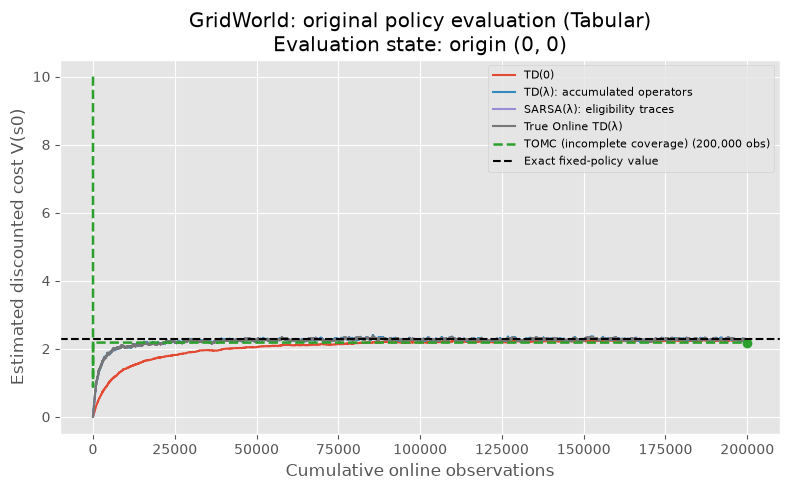

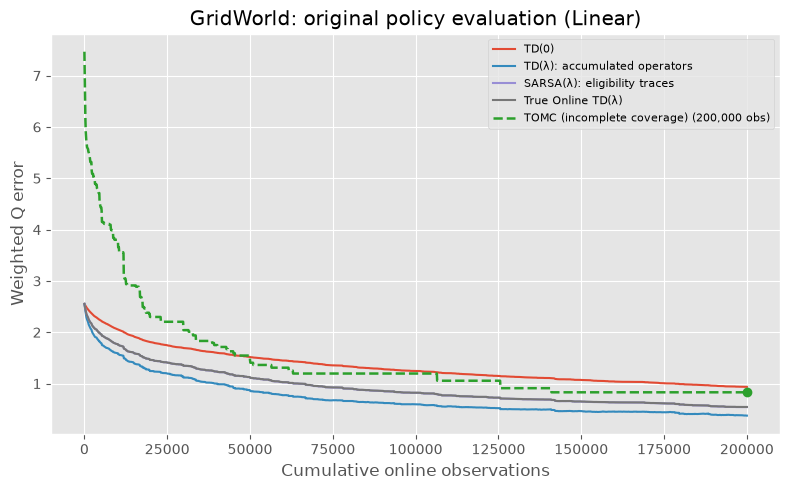

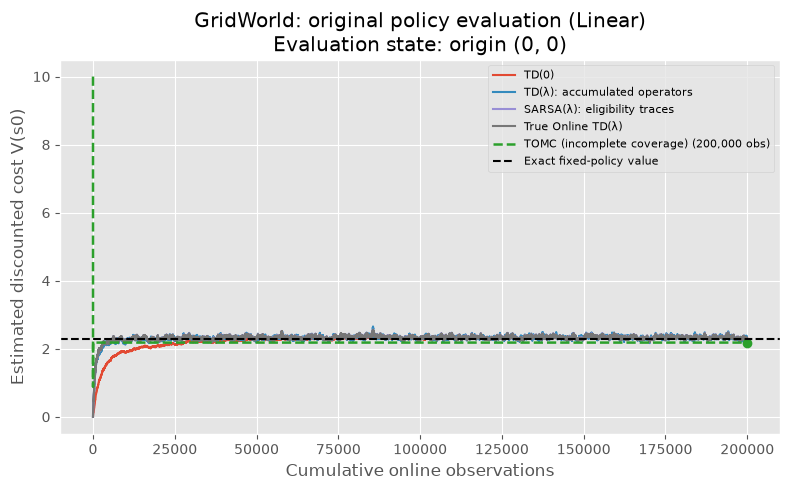

In [5]:
for name, data in all_results.items():
    for feature_name in ["Tabular", "Linear"]:
        plot_td_performance(
            data[data.features == feature_name],
            all_value_results[name][all_value_results[name].features == feature_name],
            name, feature_name, tomc_result=tomc_results["original"].get(name),
        )

### Simple hyperparameter tuning
Test three learning rates and three $\lambda$ values. TD(0) only needs the learning rate. Each candidate receives 10% of the full observation budget, and the lowest final weighted Q-error wins for each environment, representation, and method.

The exact reference Q is used only to score candidates, never for TD training. The winning parameters are then rerun from zero using the full budget and another random seed.

All four methods above participate. TD(0) has 3 candidates and each of the other
methods has 9, giving 30 candidates for each environment/feature pair:
**120 candidates total**, followed by **16 selected full runs**. Original and tuned
runs both record V(s0) at every update and save separate Q-error and V-value plots.

TOMC is an additional fixed baseline in both sets of plots, using the corresponding
comparison seed. It does not use eta or lambda and is outside this TD grid search.

In [6]:
from itertools import product

eta_grid = [0.01, 0.05, 0.1]
lam_grid = [0.0, 0.5, 0.9]
tuning_steps = max(1, N_STEPS // 10)

features = {"Tabular": tabular_features, "Linear": linear_features}

tuning_rows = []
for name in ENVIRONMENTS:
    env = Blackjack() if name == "blackjack" else GridWorld()
    pi = np.full((env.n_states, env.n_actions), 1 / env.n_actions)
    Q_ref = reference_q(env, pi)

    for feature_name, make_Phi in features.items():
        Phi = make_Phi(env)
        for method_name, td_fn in methods.items():
            lambdas = [None] if td_fn == td_zero else lam_grid
            for eta, lam in product(eta_grid, lambdas):
                args = dict(env=env, pi=pi, features=Phi, n_steps=tuning_steps,
                            eta=eta, rng=np.random.default_rng(SEED), record_every=0)
                if lam is not None:
                    args["lam"] = lam

                with np.errstate(over="ignore", invalid="ignore"):
                    result = td_fn(**args)
                    Q, n_samples = result.q, result.observations
                    error = weighted_error(Q, Q_ref)
                if not np.isfinite(error):
                    error = np.inf

                tuning_rows.append(dict(environment=name, features=feature_name,
                                        method=method_name, eta=eta, lam=lam,
                                        observations=n_samples, seed=SEED,
                                        weighted_error=error))

tuning_results = pd.DataFrame(tuning_rows)
keys = ["environment", "features", "method"]
selected_parameters = tuning_results.loc[
    tuning_results.groupby(keys).weighted_error.idxmin()
].reset_index(drop=True)

if not np.isfinite(selected_parameters.weighted_error).all():
    raise RuntimeError("Some configurations have no finite tuning result")

print(f"Grid search: {len(tuning_results)} candidates, "
      f"{tuning_steps:,} observations each, "
      f"{tuning_results.observations.sum():,} observations total")
display(selected_parameters)
tuning_results.to_csv(output / "td_grid_search.csv", index=False)
selected_parameters.to_csv(output / "td_selected_parameters.csv", index=False)

Grid search: 120 candidates, 20,000 observations each, 2,400,000 observations total


,environment,features,method,eta,lam,observations,seed,weighted_error
0,blackjack,Linear,SARSA(λ): eligibility traces,0.01,0.9,20000,42,0.291724
1,blackjack,Linear,TD(0),0.01,NaN,20000,42,0.293274
2,blackjack,Linear,TD(λ): accumulated operators,0.01,0.5,20000,42,0.291653
3,blackjack,Linear,True Online TD(λ),0.01,0.9,20000,42,0.291726
4,blackjack,Tabular,SARSA(λ): eligibility traces,0.01,0.9,20000,42,0.082102
5,blackjack,Tabular,TD(0),0.05,NaN,20000,42,0.082149
6,blackjack,Tabular,TD(λ): accumulated operators,0.05,0.0,20000,42,0.082149
7,blackjack,Tabular,True Online TD(λ),0.01,0.9,20000,42,0.082102
8,gridworld,Linear,SARSA(λ): eligibility traces,0.10,0.9,20000,42,1.063257
9,gridworld,Linear,TD(0),0.10,NaN,20000,42,1.569958


In [7]:
tuned_rows = []
full_rows = []
tuned_value_frames = []

for chosen in selected_parameters.itertuples(index=False):
    env = Blackjack() if chosen.environment == "blackjack" else GridWorld()
    pi = np.full((env.n_states, env.n_actions), 1 / env.n_actions)
    Phi = features[chosen.features](env)
    Q_ref = reference_q(env, pi)
    s_0 = env.encode(8, 3) if chosen.environment == "blackjack" else env.start

    value_history = np.empty(N_STEPS + 1, dtype=float)
    args = dict(env=env, pi=pi, features=Phi, n_steps=N_STEPS,
                eta=chosen.eta, rng=np.random.default_rng(SEED + 1),
                record_every=RECORD_EVERY,
                evaluation_state=s_0, value_history=value_history)
    if chosen.method != "TD(0)":
        args["lam"] = chosen.lam

    history = []
    result = methods[chosen.method](**args, q_history=history)
    Q, n_samples = result.q, result.observations
    if not np.isfinite(Q).all():
        raise RuntimeError(f"TD diverged: {chosen.environment}, {chosen.features}, {chosen.method}")

    snapshots = [(0, np.zeros_like(Q))] + history
    if snapshots[-1][0] != n_samples:
        snapshots.append((n_samples, Q))

    for observations, Q_t in snapshots:
        tuned_rows.append(dict(environment=chosen.environment,
                               features=chosen.features, method=chosen.method,
                               observations=observations,
                               weighted_error=weighted_error(Q_t, Q_ref),
                               estimated_value=estimated_state_value(Q_t, pi, s_0),
                               reference_value=estimated_state_value(Q_ref, pi, s_0)))
    values = state_value_performance(value_history, Q_ref, pi, s_0)
    values["environment"] = chosen.environment
    values["features"] = chosen.features
    values["method"] = chosen.method
    tuned_value_frames.append(values)
    full_rows.append(dict(tuned_rows[-1], eta=chosen.eta, lam=chosen.lam,
                          seed=SEED + 1))
    print(f"{chosen.environment} | {chosen.features} | {chosen.method}: "
          f"eta={chosen.eta:g}, lambda={chosen.lam}, observations={n_samples:,}")

tuned_results = pd.DataFrame(tuned_rows)
tuned_value_results = pd.concat(tuned_value_frames, ignore_index=True)
full_run_results = pd.DataFrame(full_rows)

tuned_results.to_csv(output / "td_tuned_history.csv", index=False)
full_run_results.to_csv(output / "td_tuned_full_runs.csv", index=False)
tuned_value_results.to_csv(output / "td_tuned_value_history.csv", index=False)
display(full_run_results)

blackjack | Linear | SARSA(λ): eligibility traces: eta=0.01, lambda=0.9, observations=200,000
blackjack | Linear | TD(0): eta=0.01, lambda=nan, observations=200,000
blackjack | Linear | TD(λ): accumulated operators: eta=0.01, lambda=0.5, observations=200,000
blackjack | Linear | True Online TD(λ): eta=0.01, lambda=0.9, observations=200,000
blackjack | Tabular | SARSA(λ): eligibility traces: eta=0.01, lambda=0.9, observations=200,000
blackjack | Tabular | TD(0): eta=0.05, lambda=nan, observations=200,000
blackjack | Tabular | TD(λ): accumulated operators: eta=0.05, lambda=0.0, observations=200,000
blackjack | Tabular | True Online TD(λ): eta=0.01, lambda=0.9, observations=200,000
gridworld | Linear | SARSA(λ): eligibility traces: eta=0.1, lambda=0.9, observations=200,000
gridworld | Linear | TD(0): eta=0.1, lambda=nan, observations=200,000
gridworld | Linear | TD(λ): accumulated operators: eta=0.05, lambda=0.9, observations=200,000
gridworld | Linear | True Online TD(λ): eta=0.1, lambda

,environment,features,method,observations,weighted_error,estimated_value,reference_value,eta,lam,seed
0,blackjack,Linear,SARSA(λ): eligibility traces,200000,0.288770,0.521805,0.540625,0.01,0.9,43
1,blackjack,Linear,TD(0),200000,0.287559,0.527058,0.540625,0.01,NaN,43
2,blackjack,Linear,TD(λ): accumulated operators,200000,0.288689,0.510650,0.540625,0.01,0.5,43
3,blackjack,Linear,True Online TD(λ),200000,0.288777,0.521682,0.540625,0.01,0.9,43
4,blackjack,Tabular,SARSA(λ): eligibility traces,200000,0.039155,0.581007,0.540625,0.01,0.9,43
5,blackjack,Tabular,TD(0),200000,0.095770,0.673703,0.540625,0.05,NaN,43
6,blackjack,Tabular,TD(λ): accumulated operators,200000,0.095770,0.673703,0.540625,0.05,0.0,43
7,blackjack,Tabular,True Online TD(λ),200000,0.039155,0.581007,0.540625,0.01,0.9,43
8,gridworld,Linear,SARSA(λ): eligibility traces,200000,0.278686,2.458360,2.287034,0.10,0.9,43
9,gridworld,Linear,TD(0),200000,0.573581,2.362810,2.287034,0.10,NaN,43


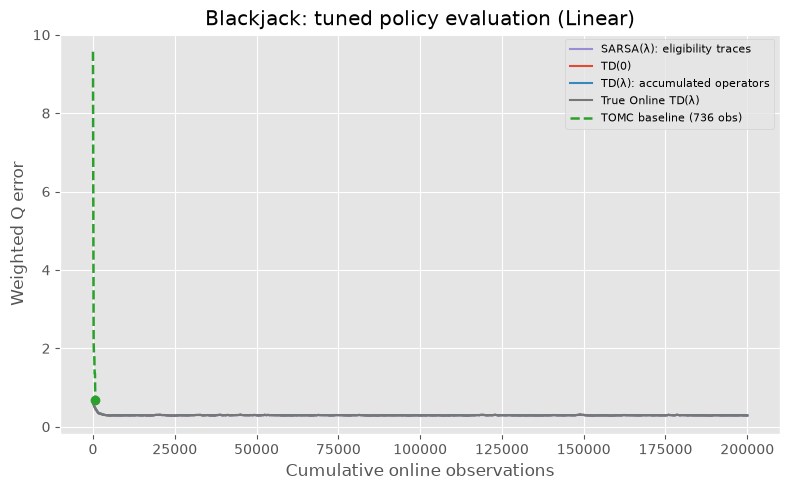

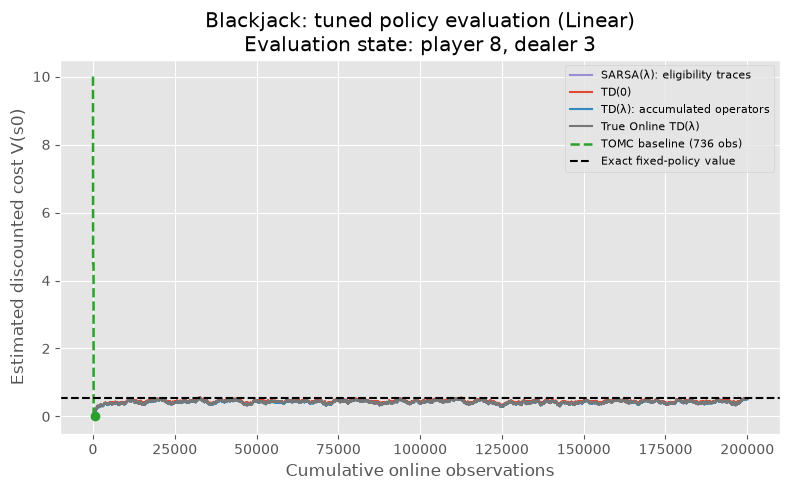

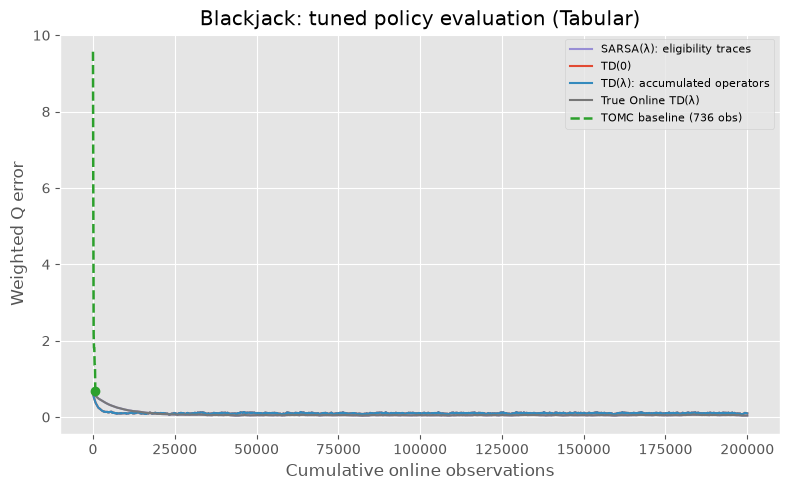

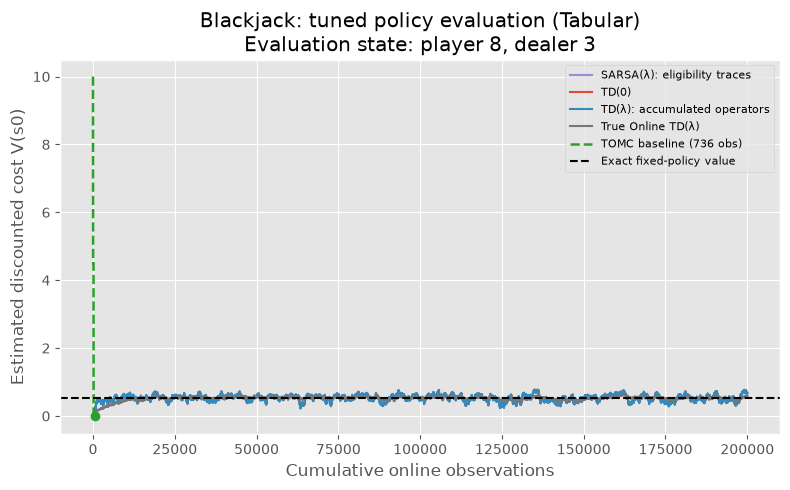

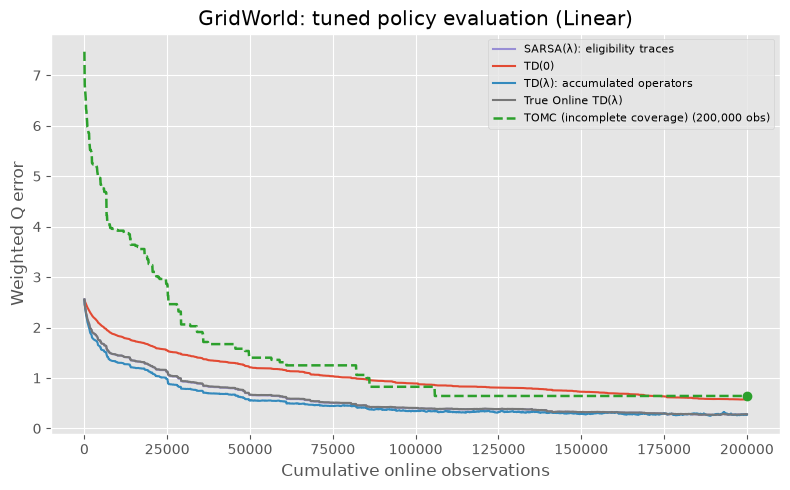

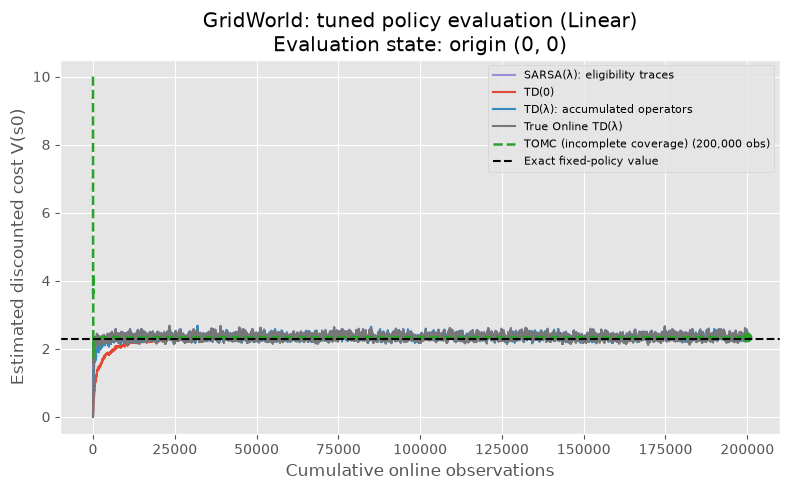

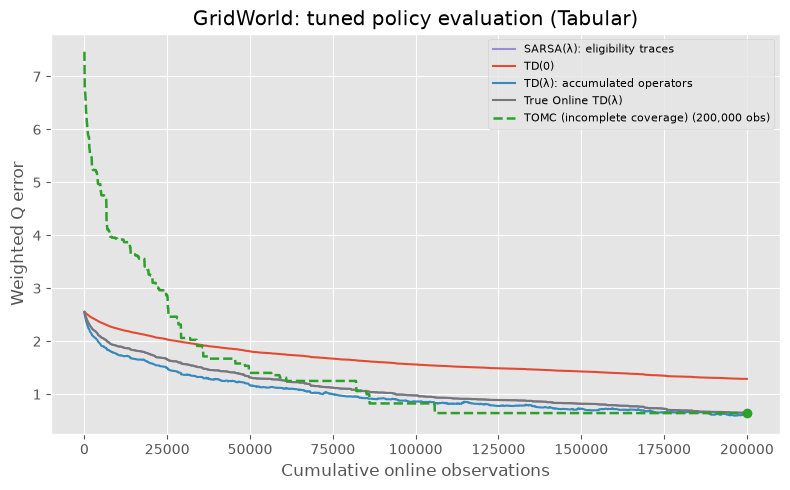

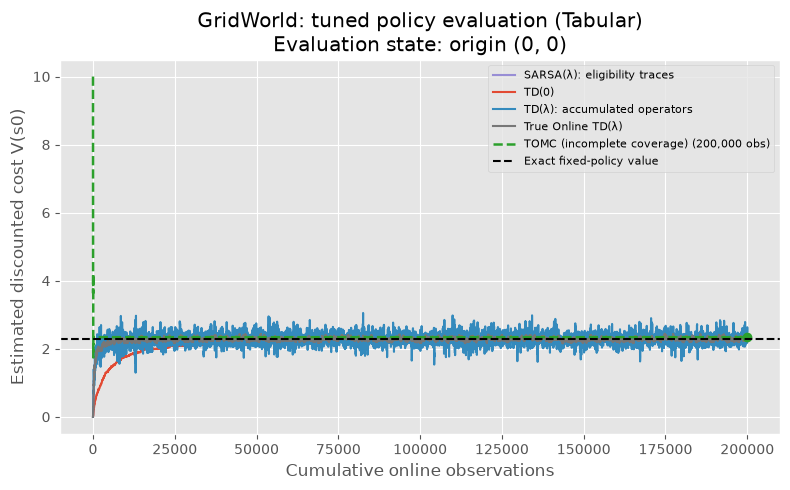

In [8]:
for (name, feature_name), data in tuned_results.groupby(["environment", "features"], sort=False):
    values = tuned_value_results[
        (tuned_value_results.environment == name) & (tuned_value_results.features == feature_name)
    ]
    plot_td_performance(data, values, name, feature_name, tuned=True,
                        tomc_result=tomc_results["tuned"].get(name))